In [47]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as pl





In [48]:
# Load Iris from the UCI repository (id=53); fall back to the copy bundled with scikit-learn if offline
try:
    from ucimlrepo import fetch_ucirepo
    iris = fetch_ucirepo(id=53)
    df = pd.concat([iris.data.features, iris.data.targets], axis=1)
    df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
    df["species"] = df["species"].str.replace("Iris-", "", regex=False)
    print("Loaded from UCI repository")
except Exception as e:
    from sklearn.datasets import load_iris   # used only to read the data
    raw = load_iris(as_frame=True)
    df = raw.frame.copy()
    df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
    df["species"] = df["species"].map(dict(enumerate(raw.target_names)))
    print("Loaded from scikit-learn fallback:", e)



Loaded from UCI repository


In [49]:
print("HEAD"); display(df.head())
print("TAIL"); display(df.tail())
print("SHAPE:", df.shape)
print("\nINFO"); df.info()
print("\nDESCRIBE"); display(df.describe())

HEAD


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


TAIL


,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


SHAPE: (150, 5)

INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

DESCRIBE


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [50]:
species_counts = df["species"].value_counts()
print(species_counts)





species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [51]:
sepal_arr = df["sepal_length"].to_numpy()
petal_arr = df["petal_length"].to_numpy()

stats = pd.DataFrame({
    "mean":   [np.mean(sepal_arr),   np.mean(petal_arr)],
    "median": [np.median(sepal_arr), np.median(petal_arr)],
    "min":    [np.min(sepal_arr),    np.min(petal_arr)],
    "max":    [np.max(sepal_arr),    np.max(petal_arr)],
}, index=["sepal_length", "petal_length"]).round(3)
stats


,mean,median,min,max
sepal_length,5.843,5.80,4.3,7.9
petal_length,3.759,4.35,1.0,6.9


In [52]:

petal_means = df.groupby("species")[["petal_length", "petal_width"]].mean().round(3)
display(petal_means)
print("Highest avg petal length:", petal_means["petal_length"].idxmax())
print("Highest avg petal width :", petal_means["petal_width"].idxmax())

,petal_length,petal_width
species,,
setosa,1.464,0.244
versicolor,4.260,1.326
virginica,5.552,2.026


Highest avg petal length: virginica
Highest avg petal width : virginica


In [53]:
top5 = df.sort_values("petal_length", ascending=False).head(5)
top5


,sepal_length,sepal_width,petal_length,petal_width,species
118,7.7,2.6,6.9,2.3,virginica
117,7.7,3.8,6.7,2.2,virginica
122,7.7,2.8,6.7,2.0,virginica
105,7.6,3.0,6.6,2.1,virginica
131,7.9,3.8,6.4,2.0,virginica


In [54]:
print("Missing values per column:"); print(df.isnull().sum())
print("\nTotal missing:", df.isnull().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Total missing: 0
Duplicated rows: 3


,sepal_length,sepal_width,petal_length,petal_width,species
9,4.9,3.1,1.5,0.1,setosa
34,4.9,3.1,1.5,0.1,setosa
37,4.9,3.1,1.5,0.1,setosa
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


In [55]:
species_means = df.groupby("species")[["sepal_length", "sepal_width", "petal_length", "petal_width"]].mean().round(3)
display(species_means)

# Pandas filtering example: flowers with petal length above the overall mean
overall_mean = np.mean(petal_arr)
above = df[df["petal_length"] > overall_mean]
print(f"Flowers with petal length above overall mean ({overall_mean:.2f}):")
print(above["species"].value_counts())

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.418,1.464,0.244
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


Flowers with petal length above overall mean (3.76):
species
virginica     50
versicolor    43
Name: count, dtype: int64


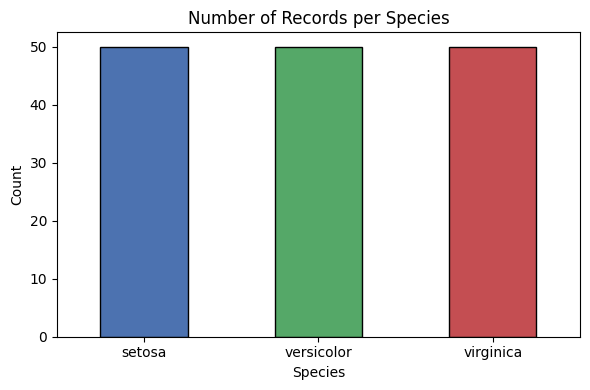

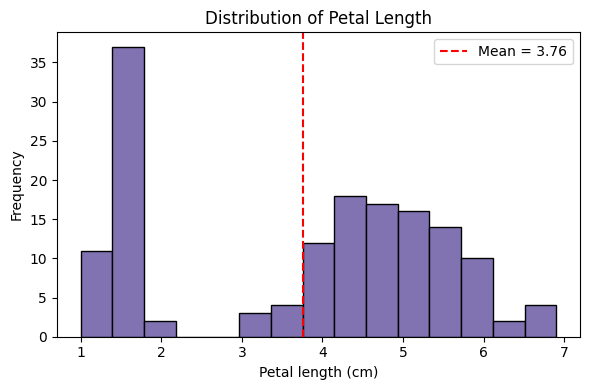

In [58]:
import matplotlib.pyplot as plt

# Chart 1: species count bar chart
plt.figure(figsize=(6, 4))
species_counts.plot(kind="bar", color=["#4c72b0", "#55a868", "#c44e52"], edgecolor="black")
plt.title("Number of Records per Species")
plt.xlabel("Species"); plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

# Chart 2: petal length histogram
plt.figure(figsize=(6, 4))
plt.hist(petal_arr, bins=15, color="#8172b2", edgecolor="black")
plt.axvline(np.mean(petal_arr), color="red", linestyle="--", label=f"Mean = {np.mean(petal_arr):.2f}")
plt.title("Distribution of Petal Length")
plt.xlabel("Petal length (cm)"); plt.ylabel("Frequency")
plt.legend(); plt.tight_layout(); plt.show()